In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


#### Data Loading

In [3]:
# Start with the dataset from Step 1

df=pd.read_csv('data/raw/Telco-Customer-Churn.csv')

ml_df = df.copy()

# Clean column values
ml_df.columns = ml_df.columns.str.strip()

# Convert numeric columns safely
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    ml_df[col] = pd.to_numeric(ml_df[col], errors="coerce")

# Handle blank TotalCharges for zero-tenure customers
zero_tenure = ml_df["tenure"].eq(0)
ml_df.loc[
    ml_df["TotalCharges"].isna() & zero_tenure,
    "TotalCharges"
] = 0

# Remove duplicate customer IDs, if present
if "customerID" in ml_df.columns:
    ml_df = ml_df.drop_duplicates(subset="customerID").copy()

# Target: 1 = churned, 0 = retained
ml_df = ml_df[ml_df["Churn"].isin(["Yes", "No"])].copy()
y = ml_df["Churn"].map({"Yes": 1, "No": 0}).astype(int)

# Remove target and identifier from model features
X = ml_df.drop(columns=["Churn", "customerID"], errors="ignore")

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())
print("\nTarget proportions:")
print(y.value_counts(normalize=True).round(3))
print("\nMissing values in target:", y.isna().sum())

Feature matrix shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64

Target proportions:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Missing values in target: 0


### Spliting the data 

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")

Training features: (5634, 19)
Testing features: (1409, 19)

Training churn rate: 26.54 %
Testing churn rate: 26.54 %


### Building the preprocessing pipeline

In [6]:
# Detect column types from training features only
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\vikra\AppData\Local\Temp\ipykernel_2176\1185914097.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [7]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    # Force dense output so all four selected models can use it
    sparse_threshold=0
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


### Machine Learning Models

In [8]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

pipelines = {
    name: Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    for name, model in models.items()
}

print("Created", len(pipelines), "model pipelines.")

Created 4 model pipelines.


### Cross Validation

In [9]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = []

for name, pipeline in pipelines.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    cv_results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_results = pd.DataFrame(cv_results).sort_values(
    by="CV ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(cv_results.round(3))

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
0,Gradient Boosting,0.804,0.681,0.489,0.569,0.849
1,Logistic Regression,0.748,0.517,0.801,0.628,0.846
2,Random Forest,0.765,0.540,0.762,0.632,0.845
3,Decision Tree,0.735,0.502,0.787,0.612,0.825


#### Selecting a model and evaluate it on the test set

In [10]:
best_model_name = cv_results.iloc[0]["Model"]
best_pipeline = pipelines[best_model_name]

print("Selected model:", best_model_name)

# Fit on all training data, then evaluate once on the held-out test set
best_pipeline.fit(X_train, y_train)

y_pred = best_pipeline.predict(X_test)
y_prob = best_pipeline.predict_proba(X_test)[:, 1]

test_metrics = {
    "Model": best_model_name,
    "Test Accuracy": accuracy_score(y_test, y_pred),
    "Test Precision": precision_score(y_test, y_pred, zero_division=0),
    "Test Recall": recall_score(y_test, y_pred, zero_division=0),
    "Test F1": f1_score(y_test, y_pred, zero_division=0),
    "Test ROC-AUC": roc_auc_score(y_test, y_prob)
}

display(pd.DataFrame([test_metrics]).round(3))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Retained", "Churned"],
    zero_division=0
))

Selected model: Gradient Boosting


,Model,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
0,Gradient Boosting,0.798,0.659,0.492,0.564,0.843



Classification report:
              precision    recall  f1-score   support

    Retained       0.83      0.91      0.87      1035
     Churned       0.66      0.49      0.56       374

    accuracy                           0.80      1409
   macro avg       0.75      0.70      0.72      1409
weighted avg       0.79      0.80      0.79      1409



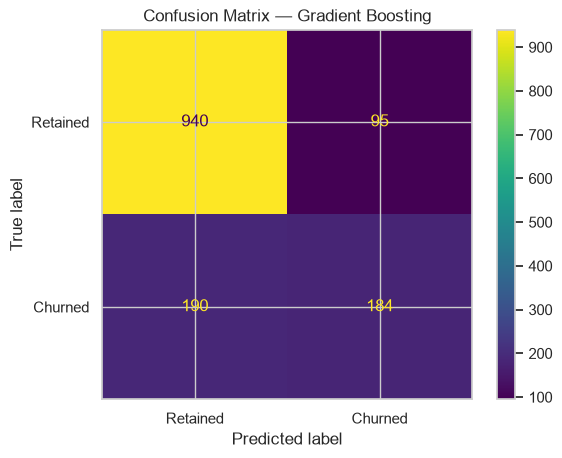

In [11]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Retained", "Churned"]
)

disp.plot()
plt.title(f"Confusion Matrix — {best_model_name}")
plt.show()

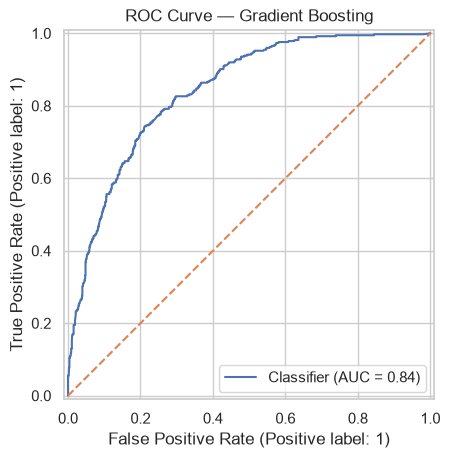

In [12]:
RocCurveDisplay.from_predictions(y_test, y_prob)

plt.title(f"ROC Curve — {best_model_name}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.show()

,Feature,Importance,Std
14,Contract,0.0527,0.0037
4,tenure,0.0510,0.0017
7,InternetService,0.0160,0.0072
8,OnlineSecurity,0.0050,0.0017
11,TechSupport,0.0048,0.0017
16,PaymentMethod,0.0035,0.0012
17,MonthlyCharges,0.0021,0.0022
6,MultipleLines,0.0015,0.0006
15,PaperlessBilling,0.0014,0.0007
18,TotalCharges,0.0013,0.0005


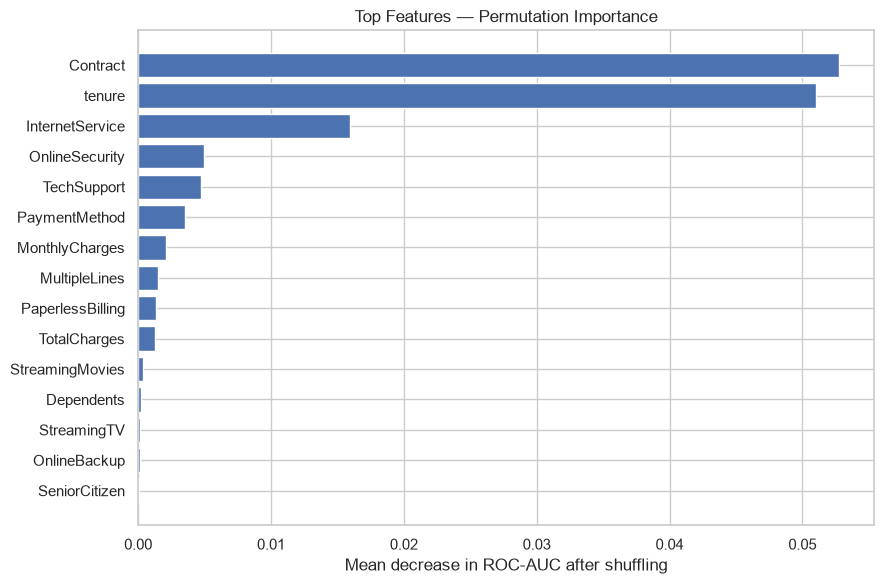

In [13]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_pipeline,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm.importances_mean,
    "Std": perm.importances_std
}).sort_values("Importance", ascending=False)

display(importance_df.head(15).round(4))

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Mean decrease in ROC-AUC after shuffling")
plt.title("Top Features — Permutation Importance")
plt.tight_layout()
plt.show()

In [14]:
Path("models").mkdir(exist_ok=True)

model_path = "models/customer_churn_pipeline.joblib"

joblib.dump(best_pipeline, model_path)

# Save the feature schema for reference
feature_schema = {
    "features": X_train.columns.tolist(),
    "target": "Churn",
    "positive_class": 1,
    "positive_class_meaning": "Customer churned",
    "selected_model": best_model_name
}

joblib.dump(
    feature_schema,
    "models/customer_churn_schema.joblib"
)

print("Saved model:", model_path)
print("Saved feature schema.")

Saved model: models/customer_churn_pipeline.joblib
Saved feature schema.


In [15]:
prediction_report = X_test.head(10).copy()

prediction_report["Actual_Churn"] = y_test.loc[
    prediction_report.index
].map({0: "No", 1: "Yes"})

prediction_report["Predicted_Churn"] = pd.Series(
    y_pred,
    index=X_test.index
).loc[prediction_report.index].map({0: "No", 1: "Yes"})

prediction_report["Churn_Probability"] = pd.Series(
    y_prob,
    index=X_test.index
).loc[prediction_report.index].round(3)

display(prediction_report)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Predicted_Churn,Churn_Probability
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20,No,No,0.063
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,No,Yes,0.633
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,...,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20,No,No,0.085
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,No,Electronic check,78.20,1468.75,No,No,0.384
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,...,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35,No,No,0.052
5748,Female,0,No,No,21,Yes,Yes,Fiber optic,No,Yes,...,Yes,Yes,Month-to-month,Yes,Credit card (automatic),99.85,1992.55,No,Yes,0.508
3568,Female,0,No,No,21,Yes,No,Fiber optic,No,Yes,...,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),99.15,1956.40,No,No,0.437
2976,Male,0,No,Yes,19,Yes,Yes,No,No internet service,No internet service,...,No internet service,No internet service,Month-to-month,Yes,Credit card (automatic),24.10,439.20,No,No,0.125
5928,Female,0,Yes,Yes,61,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,Two year,No,Credit card (automatic),19.75,1311.60,No,No,0.028
1639,Male,1,No,No,17,Yes,No,DSL,No,No,...,No,No,Month-to-month,Yes,Electronic check,45.05,770.60,Yes,No,0.342


In [16]:
Path("reports").mkdir(exist_ok=True)

cv_results.to_csv("reports/model_comparison_cv.csv", index=False)

pd.DataFrame([test_metrics]).to_csv(
    "reports/best_model_test_metrics.csv",
    index=False
)

importance_df.to_csv(
    "reports/feature_importance.csv",
    index=False
)

prediction_report.to_csv(
    "reports/sample_churn_predictions.csv",
    index=False
)

print("All Step 4 reports saved.")


All Step 4 reports saved.


In [17]:
required_objects = [
    "X_train", "X_test", "y_train", "y_test",
    "pipelines", "cv_results", "best_model_name"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        f"Missing Step 4 objects: {missing_objects}. "
        "Run the relevant Step 4 notebook cells first."
    )

print("Step 4 outputs are available.")
print("Selected baseline model:", best_model_name)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Step 4 outputs are available.
Selected baseline model: Gradient Boosting
Training rows: 5634
Testing rows: 1409


#### Tune the selected mdoel

In [18]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Search spaces for the models created in Step 4
param_spaces = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"]
    },

    "Decision Tree": {
        "model__max_depth": [3, 5, 7, 10, None],
        "model__min_samples_leaf": [5, 10, 20, 40],
        "model__class_weight": [None, "balanced"]
    },

    "Random Forest": {
        "model__n_estimators": [150, 250, 400],
        "model__max_depth": [None, 8, 12, 20],
        "model__min_samples_leaf": [2, 5, 10],
        "model__max_features": ["sqrt", 0.8],
        "model__class_weight": [None, "balanced"]
    },

    "Gradient Boosting": {
        "model__n_estimators": [75, 100, 150, 200],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "model__max_depth": [1, 2, 3],
        "model__min_samples_leaf": [5, 10, 20],
        "model__subsample": [0.8, 1.0]
    }
}

search = RandomizedSearchCV(
    estimator=pipelines[best_model_name],
    param_distributions=param_spaces[best_model_name],
    n_iter=12,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True,
    verbose=1
)

search.fit(X_train, y_train)

tuned_model = search.best_estimator_

print("Selected baseline:", best_model_name)
print("Best cross-validation ROC-AUC:", round(search.best_score_, 4))
print("Best parameters:")
print(search.best_params_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Selected baseline: Gradient Boosting
Best cross-validation ROC-AUC: 0.8504
Best parameters:
{'model__subsample': 0.8, 'model__n_estimators': 150, 'model__min_samples_leaf': 5, 'model__max_depth': 2, 'model__learning_rate': 0.05}


#### Select a business-appropriate probability threshold

In [19]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

# Generate out-of-fold probabilities on training data only
oof_prob = cross_val_predict(
    tuned_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_train,
    oof_prob,
    pos_label=1
)

# F2 gives recall greater weight than precision
beta = 2
f2_scores = (
    (1 + beta**2) * precision[:-1] * recall[:-1]
    / (beta**2 * precision[:-1] + recall[:-1] + 1e-12)
)

best_idx = np.argmax(f2_scores)
best_threshold = float(thresholds[best_idx])

print("Selected threshold:", round(best_threshold, 3))
print("OOF precision:", round(precision[best_idx], 3))
print("OOF recall:", round(recall[best_idx], 3))
print("OOF F2-score:", round(f2_scores[best_idx], 3))

Selected threshold: 0.141
OOF precision: 0.444
OOF recall: 0.912
OOF F2-score: 0.754


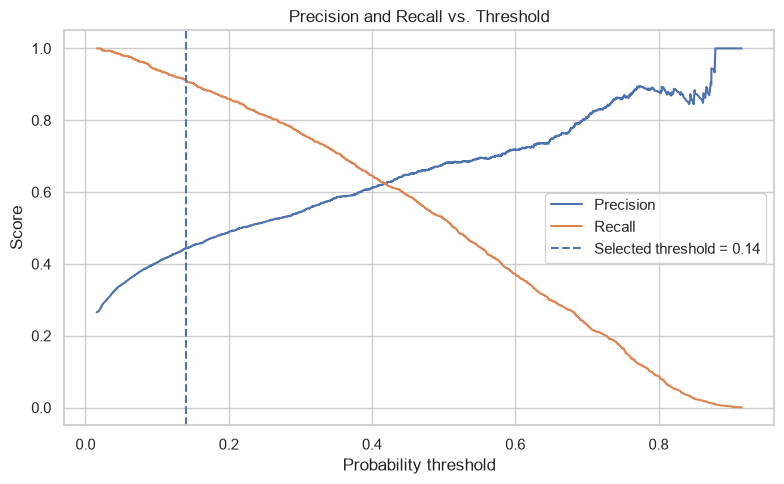

In [20]:
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")
plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Selected threshold = {best_threshold:.2f}"
)
plt.xlabel("Probability threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs. Threshold")
plt.legend()
plt.tight_layout()
plt.show()

,Threshold,Accuracy,Precision,Recall,F1,F2,ROC_AUC,Average_Precision
0,0.141,0.666,0.438,0.901,0.589,0.744,0.846,0.665


              precision    recall  f1-score   support

    Retained       0.94      0.58      0.72      1035
     Churned       0.44      0.90      0.59       374

    accuracy                           0.67      1409
   macro avg       0.69      0.74      0.65      1409
weighted avg       0.81      0.67      0.68      1409



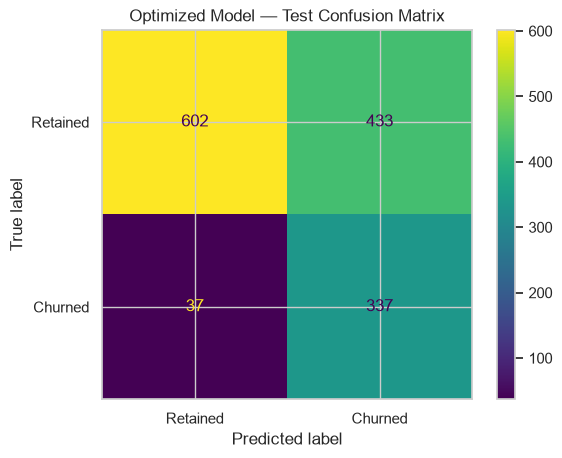

In [21]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, roc_auc_score,
    average_precision_score, confusion_matrix,
    classification_report
)

tuned_model.fit(X_train, y_train)

test_prob = tuned_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

optimized_metrics = {
    "Threshold": best_threshold,
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "Recall": recall_score(y_test, test_pred, zero_division=0),
    "F1": f1_score(y_test, test_pred, zero_division=0),
    "F2": fbeta_score(y_test, test_pred, beta=2, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, test_prob),
    "Average_Precision": average_precision_score(y_test, test_prob)
}

display(pd.DataFrame([optimized_metrics]).round(3))

print(classification_report(
    y_test,
    test_pred,
    target_names=["Retained", "Churned"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    display_labels=["Retained", "Churned"]
)
plt.title("Optimized Model — Test Confusion Matrix")
plt.show()

Brier score: 0.1353


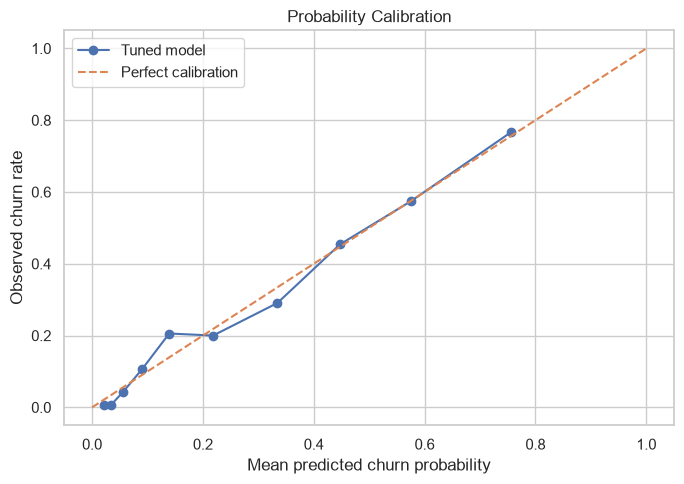

In [22]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

fraction_positive, mean_predicted = calibration_curve(
    y_test,
    test_prob,
    n_bins=10,
    strategy="quantile"
)

brier = brier_score_loss(y_test, test_prob)
print("Brier score:", round(brier, 4))

plt.figure(figsize=(7, 5))
plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="Tuned model"
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.xlabel("Mean predicted churn probability")
plt.ylabel("Observed churn rate")
plt.title("Probability Calibration")
plt.legend()
plt.tight_layout()
plt.show()

#### Create customer-risk segments

In [23]:
# Customer-level report for the held-out test set
risk_report = X_test.copy()

risk_report["Actual_Churn"] = y_test
risk_report["Churn_Probability"] = test_prob
risk_report["Predicted_Churn"] = test_pred

risk_report["Risk_Segment"] = pd.cut(
    risk_report["Churn_Probability"],
    bins=[-np.inf, 0.40, 0.70, np.inf],
    labels=["Low", "Medium", "High"],
    right=False
)

risk_report["Risk_Segment"] = risk_report["Risk_Segment"].astype(str)

risk_report = risk_report.sort_values(
    "Churn_Probability",
    ascending=False
)

display(risk_report.head(20))

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Churn_Probability,Predicted_Churn,Risk_Segment
3380,Male,1,Yes,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,95.10,95.10,1,0.911896,1,High
6866,Male,0,No,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,95.45,95.45,1,0.897040,1,High
4585,Female,1,No,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,85.05,85.05,1,0.887821,1,High
2797,Male,0,No,No,3,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,100.95,329.95,1,0.879382,1,High
6623,Male,1,No,No,1,Yes,Yes,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,76.45,76.45,1,0.874494,1,High
6365,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,101.95,700.85,1,0.869978,1,High
2631,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,99.25,665.45,1,0.869978,1,High
2246,Female,0,Yes,Yes,1,Yes,Yes,Fiber optic,Yes,No,...,Yes,Month-to-month,Yes,Electronic check,102.45,102.45,1,0.867865,1,High
6748,Female,1,No,No,1,Yes,No,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,85.00,85.00,1,0.862460,1,High
2464,Female,0,No,No,1,Yes,Yes,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,77.15,77.15,1,0.854338,1,High


In [24]:
risk_summary = (
    risk_report
    .groupby("Risk_Segment", observed=True)
    .agg(
        customers=("Churn_Probability", "size"),
        avg_predicted_risk=("Churn_Probability", "mean"),
        actual_churn_rate=("Actual_Churn", "mean"),
        avg_monthly_charges=("MonthlyCharges", "mean")
    )
    .reset_index()
)

risk_summary["avg_predicted_risk_pct"] = (
    100 * risk_summary["avg_predicted_risk"]
).round(2)

risk_summary["actual_churn_rate_pct"] = (
    100 * risk_summary["actual_churn_rate"]
).round(2)

display(risk_summary.round(3))

,Risk_Segment,customers,avg_predicted_risk,actual_churn_rate,avg_monthly_charges,avg_predicted_risk_pct,actual_churn_rate_pct
0,High,104,0.784,0.817,81.539,78.42,81.73
1,Low,989,0.128,0.123,58.579,12.84,12.34
2,Medium,316,0.531,0.528,75.589,53.15,52.85


In [25]:
# Illustrative assumptions — replace with business-provided values
contact_cost = 200
retention_success_rate = 0.15
retention_months = 6

high_risk = risk_report[
    risk_report["Risk_Segment"] == "High"
].copy()

customers_contacted = len(high_risk)
campaign_cost = customers_contacted * contact_cost

expected_retained_customers = (
    customers_contacted * retention_success_rate
)

# Estimated retained billings, not profit or guaranteed revenue
estimated_retained_billings = (
    expected_retained_customers
    * high_risk["MonthlyCharges"].mean()
    * retention_months
    if customers_contacted > 0
    else 0
)

estimated_net_billings_after_contact_cost = (
    estimated_retained_billings - campaign_cost
)

impact_report = pd.DataFrame([{
    "customers_contacted": customers_contacted,
    "assumed_contact_cost": contact_cost,
    "assumed_success_rate": retention_success_rate,
    "assumed_retention_months": retention_months,
    "estimated_campaign_cost": campaign_cost,
    "expected_retained_customers": expected_retained_customers,
    "estimated_retained_billings": estimated_retained_billings,
    "estimated_billings_minus_contact_cost":
        estimated_net_billings_after_contact_cost
}])

display(impact_report.round(2))

,customers_contacted,assumed_contact_cost,assumed_success_rate,assumed_retention_months,estimated_campaign_cost,expected_retained_customers,estimated_retained_billings,estimated_billings_minus_contact_cost
0,104,200,0.15,6,20800,15.6,7632.09,-13167.91


In [26]:
from pathlib import Path
import joblib

Path("models").mkdir(exist_ok=True)
Path("reports").mkdir(exist_ok=True)

# Save fitted model pipeline
joblib.dump(
    tuned_model,
    "models/customer_churn_optimized_pipeline.joblib"
)

# Save the threshold and risk-band definitions
deployment_config = {
    "model_name": best_model_name,
    "decision_threshold": best_threshold,
    "risk_thresholds": {
        "low_upper": 0.40,
        "medium_upper": 0.70
    },
    "positive_class": 1,
    "positive_class_meaning": "Churn"
}

joblib.dump(
    deployment_config,
    "models/customer_churn_config.joblib"
)

# Save evaluation and business reports
pd.DataFrame([optimized_metrics]).to_csv(
    "reports/optimized_model_metrics.csv",
    index=False
)

risk_report.to_csv(
    "reports/customer_risk_segments.csv",
    index=True
)

risk_summary.to_csv(
    "reports/risk_segment_summary.csv",
    index=False
)

impact_report.to_csv(
    "reports/retention_business_scenario.csv",
    index=False
)

print("Step 5 model and reports saved successfully.")

Step 5 model and reports saved successfully.


In [27]:
loaded_model = joblib.load(
    "models/customer_churn_optimized_pipeline.joblib"
)

loaded_config = joblib.load(
    "models/customer_churn_config.joblib"
)

# Predict the probability for one held-out customer
one_customer = X_test.iloc[[0]]
probability = loaded_model.predict_proba(one_customer)[0, 1]

threshold = loaded_config["decision_threshold"]
prediction = int(probability >= threshold)

print("Churn probability:", round(probability, 3))
print("Predicted churn:", "Yes" if prediction == 1 else "No")
print("Threshold used:", round(threshold, 3))

Churn probability: 0.045
Predicted churn: No
Threshold used: 0.141
